# EL JUEGO DE LA SIMULACIÓN — Grupo X
**Escenario 3: tasas de mutación en distintas regiones genómicas**

**Idea del juego:** el jugador ve una secuencia de referencia y el histograma de conteos de mutaciones en 500 réplicas de esa región, debe
(1) estimar la tasa media de mutación y (2) decidir si los datos siguen una **Poisson** o una
**binomial negativa (NB)**.

**Cómo usar este notebook en Google Colab:** ejecutá las celdas de arriba hacia abajo
(`Shift+Enter`). Cada sección se puede volver a correr por separado, siempre que antes hayas corrido
la celda de **configuración**.

**Estructura:**
1. Configuración
2. Generación de datos
3. Validación
4. Lógica del juego
5. Demostración

## 1. Configuración
**Qué hace esta sección:** crea el generador de números aleatorios y define los parámetros del juego.
Se corre primero, porque todas las demás secciones usan estas variables.

### El generador aleatorio y el tamaño de muestra
- **`rng`**: generador de números aleatorios de NumPy. Todo lo aleatorio del notebook sale de él.
  La **semilla fija (2024)** hace que al repetir la corrida salgan los mismos números y así la validación es reproducible.
- **`N = 500`**: cantidad de **réplicas** por ronda, cuántos datos ve el jugador. Cada réplica es una copia
  independiente de la región y da un conteo de mutaciones (0, 1, 2…). Con muchas réplicas el histograma se parece más
  a la distribución real y los tests detectan mejor las diferencias.

### Los rangos que se sortean en cada ronda
Son decisiones de diseño del juego, no constantes biológicas.

| Variable | Valores | Qué significa |
|---|---|---|
| `LONG_MIN`, `LONG_MAX` | 50 y 500 | Longitud de la región, en nucleótidos |
| `TASA_SITIO_MIN`, `TASA_SITIO_MAX` | 0.004 y 0.02 | Mutaciones esperadas **por nucleótido** en el período observado |
| `ALFA_MIN`, `ALFA_MAX` | 0.5 y 2.5 | Heterogeneidad entre regiones (solo se usa en el modelo 2, binomial negativa) |

**Tasa por sitio.** Es el número esperado de mutaciones de **un solo nucleótido** durante el período observado.
Un valor de 0.004 significa 4 chances en 1000 de que ese nucleótido mute, y 0.02 significa 2 en 100.
Cada ronda sortea un valor entre esos extremos.

**Media por región**: es lo que el jugador tiene que estimar. Una región más larga tiene más nucleótidos, y por eso
más mutaciones esperadas:

`media por región = tasa_sitio × longitud`

- Mínimo: región corta con tasa baja, 50 × 0.004 = **0.2** mutaciones por región.
- Máximo: región larga con tasa alta, 500 × 0.02 = **10** mutaciones por región.
- Ejemplo: una región de 200 nucleótidos con tasa 0.01 tiene media 200 × 0.01 = **2**. Ese es el valor que el jugador
  tiene que acertar. Se le pide como "mutaciones por región", no como tasa por nucleótido.

**Alfa (α).** Mide cuánto **difieren las regiones entre sí** en su tasa de mutación.
- α chico (0.5): las regiones son muy distintas. Algunas casi no mutan y otras tienen muchísimas mutaciones. La sobredispersión es fuerte.
- α grande (2.5): las regiones se parecen más entre sí. La sobredispersión es más leve.
- La varianza de los datos es `media + media²/α`, así que cuanto menor es α, mayor es la varianza respecto de la media.
- Si la ronda es Poisson (modelo 1), α no se usa, porque todas las regiones comparten la misma tasa.

### Supuesto del escenario
Todas las réplicas de una ronda tienen la **misma longitud y el mismo período de observación** (igual exposición).
Así, cualquier diferencia entre réplicas en el modelo 2 se debe a que las regiones tienen tasas distintas,
y no a que se las midió de forma desigual.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# 1. CONFIGURACIÓN
rng = np.random.default_rng(seed=2024)  # SEMILLA FIJA
N = 500                                  # regiones por ronda
LONG_MIN, LONG_MAX = 50, 500             # longitud de la región (nt), ambos extremos incluidos
TASA_SITIO_MIN, TASA_SITIO_MAX = 0.004, 0.02   # tasa por nucleótido y por período
ALFA_MIN, ALFA_MAX = 0.5, 2.5            # heterogeneidad Gamma (modelo NB)

## 2. Generación de datos
**Qué hace esta sección:** define cómo se simulan los conteos de mutaciones y cómo se arma cada ronda del juego.

### Qué estamos simulando
Se cuentan las mutaciones en 500 copias (réplicas) de una región del genoma. Cada copia da un número entero
(0, 1, 2, 3…). El problema del juego es **adivinar qué regla de azar generó esos números**.
Hay dos reglas posibles (modelos).

### Modelo 1: Poisson
**Idea:** todas las regiones mutan igual de "fácil".

La Poisson sirve cuando se cumplen tres cosas:
- **Eventos raros:** de muchos nucleótidos, pocos mutan.
- **Independientes:** que mute uno no hace más probable que mute el de al lado.
- **Tasa constante:** todas las regiones tienen la misma chance.

Se escribe `X ~ Poisson(λ)`. Una consecuencia importante es que **el promedio y la varianza son iguales**:
`E[X] = Var[X] = λ`. La varianza mide qué tan desparramados están los datos. Si el promedio es 4, la varianza también es 4.

### Modelo 2: Gamma-Poisson (= binomial negativa)
**Idea:** las regiones **no** mutan igual de "fácil". Algunas son tranquilas y otras son hotspots (distinta replicación,
distinto contexto, etc.).

Se genera en dos pasos:
1. **Cada región recibe su propia tasa**, sorteada con una Gamma: `λᵢ ~ Gamma(α, escala = μ/α)`.
   Una región puede quedar con tasa 0.5 y otra con 15. El promedio de todas las tasas sigue siendo `μ`.
2. **Con su tasa, cada región saca su conteo** con una Poisson: `Xᵢ ~ Poisson(λᵢ)`.
   La región de tasa 0.5 casi siempre da 0 o 1, y la de tasa 15 da un valor cercano a 15.

Al mezclar los dos pasos, el resultado tiene un nombre propio: **binomial negativa**, `X ~ NB(r = α, p = α/(α+μ))`.
Gamma-Poisson y binomial negativa son lo mismo escrito de dos formas.

**Sobredispersión.** La media sigue siendo `E[X] = μ`, pero la varianza es mayor: `Var[X] = μ + μ²/α > μ`.
El término extra `μ²/α` es la diferencia entre regiones. Cuando la varianza supera a la media se llama **sobredispersión**.
- α grande (por ejemplo 100): las regiones casi no se diferencian y los datos se parecen a una Poisson.
- α chico (por ejemplo 0.5): las regiones son muy distintas y la varianza se dispara.
- Ejemplo con μ = 4: con α = 1 la varianza es 4 + 16/1 = **20**; con α = 100 es 4 + 16/100 = **4.16**, casi 4.

### Resumen de los dos modelos
| | Poisson | Gamma-Poisson (NB) |
|---|---|---|
| ¿Todas las regiones iguales? | Sí | No, cada una tiene su tasa |
| Media | μ | μ |
| Varianza | μ | μ + μ²/α (mayor que μ) |
| Forma del histograma | Campana alrededor de μ | Muchos ceros y cola larga |

### Dos aclaraciones sobre el juego
- **Por qué la media depende de la longitud.** Si cada nucleótido muta con una chance muy chica `r`, una región de `L`
  nucleótidos es la suma de `L` de esas chances, y esa suma es Poisson con media `r·L`. Por eso la media de la ronda es
  `tasa_sitio × longitud`. Por ejemplo, con `r = 0.01` y `L = 200` se esperan 2 mutaciones.
- **La secuencia es solo contexto visual.** La secuencia de letras A, T, C, G que ve el jugador se sortea al azar
  y no influye en los conteos.

In [ ]:
# 2. GENERACIÓN DE DATOS
def generar_datos(rng, n, media, alfa=None):
    """
    Genera n conteos de mutaciones (uno por región).

    - alfa=None  -> Poisson(media): todas las regiones comparten la misma tasa.
    - alfa=float -> Gamma-Poisson: cada región tiene su propia tasa
                    lambda_i ~ Gamma(shape=alfa, scale=media/alfa) y luego X_i ~ Poisson(lambda_i).
                    Equivale a una binomial negativa con E[X]=media, Var[X]=media+media^2/alfa.
    """
    if alfa is None:
        return rng.poisson(media, size=n)
    tasas_regionales = rng.gamma(shape=alfa, scale=media / alfa, size=n)
    return rng.poisson(tasas_regionales)


def generar_ronda(rng, n=N):
    """
    Sortea una ronda completa. El modelo (1 = Poisson, 2 = Gamma-Poisson/NB) cambia al azar en cada ronda.
    Devuelve (datos, modelo, secuencia, tasa_sitio, media_real, alfa).
    """
    modelo = int(rng.choice([1, 2]))
    longitud = int(rng.integers(LONG_MIN, LONG_MAX + 1))
    secuencia = "".join(rng.choice(list("ATCG"), size=longitud))
    tasa_sitio = float(rng.uniform(TASA_SITIO_MIN, TASA_SITIO_MAX))
    media_real = tasa_sitio * longitud
    alfa = None if modelo == 1 else float(rng.uniform(ALFA_MIN, ALFA_MAX))
    datos = generar_datos(rng, n, media_real, alfa)
    return datos, modelo, secuencia, tasa_sitio, media_real, alfa


def nb_scipy(media, alfa):
    """Distribución NB de scipy equivalente a la Gamma-Poisson (r=alfa, p=alfa/(alfa+media))."""
    return stats.nbinom(n=alfa, p=alfa / (alfa + media))


# Prueba rápida
datos_prueba = generar_datos(rng, N, media=4.0)
print("Primeros 20 conteos:", datos_prueba[:20])
print("Media:", datos_prueba.mean().round(3), "| Varianza:", datos_prueba.var(ddof=1).round(3))

Primeros 20 conteos: [5 1 4 1 5 4 3 5 4 5 2 4 3 5 3 1 0 3 5 4]
Media: 4.09 | Varianza: 3.834


### Qué hace el código de esta sección
**`generar_datos(rng, n, media, alfa=None)`** es el corazón de la simulación.
```python
if alfa is None:
    return rng.poisson(media, size=n)
tasas_regionales = rng.gamma(shape=alfa, scale=media / alfa, size=n)
return rng.poisson(tasas_regionales)
```
- **Sin `alfa`** (modelo 1): genera `n` conteos Poisson, todos con la misma media.
- **Con `alfa`** (modelo 2): primero sortea una tasa distinta por región con una Gamma, y después sortea el conteo de
  cada región con una Poisson que usa su propia tasa. El resultado es una binomial negativa.
- `scale = media/alfa` hace que la Gamma tenga promedio exactamente `media`, así que los dos modelos son comparables.

**`generar_ronda(rng, n)`** arma una ronda completa. Sortea el modelo (1 o 2), la longitud, la secuencia, la tasa por
nucleótido y, si es modelo 2, `alfa`. Calcula `media_real = tasa_sitio × longitud`, llama a `generar_datos` y devuelve
todo, incluidas las respuestas correctas, para que el juego pueda puntuar después.

**La celda de "prueba rápida"** genera 500 conteos Poisson con media 4 y muestra los primeros 20, su media y su varianza.
Sirve para comprobar que la función anda; ya acá se ve que la media y la varianza son parecidas.


## 3. Validación
**Qué hace esta sección:** comprueba que la simulación es correcta. Compara los datos generados con la distribución
teórica y muestra qué pasa cuando se usa el modelo equivocado.

### La idea
- Los **datos** son los conteos que salieron de la simulación.
- La **distribución teórica** es lo que *debería* pasar si esos datos vinieran de un modelo con ciertos parámetros.
- Si los datos y la teoría coinciden, la simulación funciona. Si no coinciden, ese modelo no describe a los datos.

### De dónde salen los valores teóricos
Salen de las **fórmulas de la distribución**. Al escribir `stats.poisson(mu=4.0)`, SciPy crea
una Poisson con λ = 4 y sabe calcular:

| Qué se pide | Qué devuelve |
|---|---|
| `dist.stats(moments="mv")` | media y varianza teóricas (Poisson: ambas valen λ; NB: μ y μ + μ²/α) |
| `dist.pmf(x)` | probabilidad teórica de observar exactamente `x` mutaciones |
| `dist.ppf(q)` | cuantil teórico: el valor que deja una probabilidad `q` por debajo |
| `dist.sf(k)` | probabilidad teórica de superar `k` (la cola) |

### Las tres herramientas de validación
1. **Media y varianza empíricas vs teóricas.** Las empíricas se calculan sobre los datos, y las teóricas salen de la tabla
   de arriba. Nunca coinciden exacto, porque con 500 datos hay azar de muestreo, pero deben estar cerca.
   El **índice de dispersión** (`varianza / media`) resume la comparación: ≈ 1 es compatible con Poisson y > 1 indica sobredispersión.
2. **QQ-plot.** Se ordenan los datos de menor a mayor y se comparan con los cuantiles que la teoría esperaría en cada
   posición. Cada punto es (cuantil teórico, cuantil observado). Si el modelo es correcto, los puntos caen sobre la recta
   `y = x`. Como los conteos son enteros hay empates, por eso se ven **escalones** (es normal).
3. **Test de bondad de ajuste χ².** Para cada valor posible (0, 1, 2…) compara cuántas regiones se **observaron** con
   cuántas se **esperarían**. Se agrupan categorías hasta que lo esperado sea ≥ 5 en cada una.
   `H0`: los datos vienen de esa distribución. Un **p-valor ≥ 0.05** significa que no hay evidencia contra el modelo,
   y un **p < 0.05** significa que se rechaza el modelo. Los grados de libertad son `categorías − 1 − parámetros estimados`.

### Qué parámetros se le pasan a la teoría
- **Parámetros verdaderos** (por ejemplo `mu=4.0`, el valor con el que se generaron los datos): la comparación es limpia,
  porque responde "¿los datos salieron como dice la teoría?".
- **Parámetros estimados de los datos** (por ejemplo `mu=datos.mean()`): la comparación de medias es **trivial**, porque se compara
  la media de los datos consigo misma. Lo que sí aporta es la **varianza** y el test χ². Por eso en estos casos se resta
  1 grado de libertad (`parametros_estimados=1`).

### Cómo interpretar los resultados
| Lo que se ve | Qué significa |
|---|---|
| Índice ≈ 1, p alto, puntos sobre la recta | El modelo Poisson ajusta |
| Índice mucho mayor que 1, p ≈ 0, puntos que se separan de la recta hacia arriba | Hay sobredispersión y Poisson no sirve |
| Con binomial negativa: p alto y puntos sobre la recta | La binomial negativa ajusta |

**Cuidado con la conclusión:** un p-valor alto no prueba que el modelo sea el verdadero, solo que los datos no lo contradicen.

In [ ]:
# 3. VALIDACIÓN
def chi2_bondad_ajuste(datos, dist, parametros_estimados=1, minimo_esperado=5):
    """Test chi-cuadrado para una distribución discreta. Devuelve (estadístico, gl, p-valor)."""
    n = len(datos)
    k = int(datos.max())
    valores = np.arange(k + 1)
    observado = np.bincount(datos, minlength=k + 1).astype(float)
    esperado = n * dist.pmf(valores)
    esperado[-1] += n * dist.sf(k)          # la última categoría absorbe toda la cola

    # Agrupar categorías contiguas hasta que esperado >= minimo_esperado
    obs_g, esp_g, o_acum, e_acum = [], [], 0.0, 0.0
    for o, e in zip(observado, esperado):
        o_acum += o
        e_acum += e
        if e_acum >= minimo_esperado:
            obs_g.append(o_acum)
            esp_g.append(e_acum)
            o_acum = e_acum = 0.0
    if e_acum > 0 and esp_g:                # sobrante -> se suma a la última categoría
        obs_g[-1] += o_acum
        esp_g[-1] += e_acum

    obs_g, esp_g = np.array(obs_g), np.array(esp_g)
    estadistico = np.sum((obs_g - esp_g) ** 2 / esp_g)
    gl = len(obs_g) - 1 - parametros_estimados
    if gl < 1:
        return estadistico, gl, np.nan
    return estadistico, gl, stats.chi2.sf(estadistico, gl)


def validar(datos, distribucion, parametros_estimados=1, graficar=True, **params):
    """
    Compara datos simulados con la distribución teórica.
      - Media y varianza empíricas vs teóricas
      - QQ-plot (discreto)
      - Test de bondad de ajuste chi-cuadrado
    Ejemplo: validar(datos, stats.poisson, mu=4.0)
             validar(datos, stats.nbinom, n=alfa, p=alfa/(alfa+media))
    """
    dist = distribucion(**params)
    media_t, var_t = dist.stats(moments="mv")
    media_e, var_e = datos.mean(), datos.var(ddof=1)
    estad, gl, p = chi2_bondad_ajuste(datos, dist, parametros_estimados)

    print(f"Distribución teórica: {distribucion.name}  {params}")
    print(f"  Media    -> empírica {media_e:.3f} | teórica {float(media_t):.3f}")
    print(f"  Varianza -> empírica {var_e:.3f} | teórica {float(var_t):.3f}")
    print(f"  Índice de dispersión (s²/media): {var_e / media_e:.3f}   (≈1 si es Poisson)")
    print(f"  Chi-cuadrado: estadístico={estad:.2f}, gl={gl}, p-valor={p:.4f}")
    if np.isnan(p):
        print("  -> Test no calculable (muy pocas categorías con frecuencia esperada >= 5).")
    elif p >= 0.05:
        print("  -> NO se rechaza H0: el ajuste es razonable.")
    else:
        print("  -> Se RECHAZA H0: la distribución no ajusta a los datos.")

    if graficar:
        fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))

        # (a) Histograma observado vs pmf teórica
        x = np.arange(int(datos.max()) + 1)
        obs = 100 * np.bincount(datos, minlength=len(x)) / len(datos)
        ejes[0].bar(x, obs, alpha=0.6, label="Observada")
        ejes[0].plot(x, 100 * dist.pmf(x), "ro-", label="Teórica")
        ejes[0].set_xlabel("Mutaciones por región")
        ejes[0].set_ylabel("Frecuencia (%)")
        ejes[0].set_title("Frecuencias observadas vs teóricas")
        ejes[0].legend()

        # (b) QQ-plot discreto
        prob = (np.arange(1, len(datos) + 1) - 0.5) / len(datos)
        teoricos = dist.ppf(prob)
        observados = np.sort(datos)
        tope = max(teoricos.max(), observados.max())
        ejes[1].scatter(teoricos, observados, s=12, alpha=0.6, label="Cuantiles")
        ejes[1].plot([0, tope], [0, tope], "r--", label="y = x")
        ejes[1].set_xlabel("Cuantiles teóricos")
        ejes[1].set_ylabel("Cuantiles observados")
        ejes[1].set_title("QQ-plot (los escalones son normales en conteos)")
        ejes[1].legend()

        plt.tight_layout()
        plt.show()

    return {"media_emp": media_e, "var_emp": var_e, "chi2": estad, "gl": gl, "p": p}

### Qué hace el código de esta sección
**`chi2_bondad_ajuste(datos, dist, parametros_estimados, minimo_esperado)`** calcula el test χ².
1. Cuenta las regiones observadas por valor (`np.bincount`) y calcula las esperadas (`n * dist.pmf`).
2. La última categoría absorbe toda la cola (`dist.sf(k)`), para que las probabilidades sumen 1.
3. Agrupa categorías vecinas hasta que la frecuencia esperada sea ≥ 5, porque el test es poco confiable con categorías casi vacías.
4. Calcula el estadístico `Σ (obs − esp)² / esp`, los grados de libertad y el p-valor con `stats.chi2.sf`.
   Si quedan muy pocas categorías, el p-valor no se puede calcular y devuelve `nan`.

**`validar(datos, distribucion, parametros_estimados=1, graficar=True, **params)`** junta las tres herramientas:
- Crea la distribución teórica con los parámetros que se le pasan, por ejemplo `validar(datos, stats.poisson, mu=4.0)`.
- Imprime media y varianza empíricas contra teóricas, el índice de dispersión y el resultado del test χ².
- Dibuja a la izquierda el histograma observado contra la curva teórica (`pmf`), y a la derecha el QQ-plot.
- Devuelve un diccionario con los números (media, varianza, χ², grados de libertad y p-valor) por si querés usarlos en el informe.

**Objetivo de la sección:** cumplir con "hay validación" (comparar media y varianza con las teóricas, QQ-plot y test de bondad de ajuste),
y mostrar el desafío del escenario: cuando hay sobredispersión, Poisson falla.

## 4. Lógica del juego
**Qué hace esta sección:** implementa el juego. Genera cada ronda, muestra los datos al jugador, recibe sus respuestas,
las puntúa y muestra la validación.

### Reglas
- Son **3 rondas**. En cada una se sortean la longitud de la región, la tasa por nucleótido y el modelo
  (**Poisson o binomial negativa, 50 % cada uno**, de forma independiente entre rondas).
- El jugador ve la secuencia de referencia y un histograma de 500 réplicas, **sin saber el modelo**, y responde dos cosas:
  1. su estimación de la media de mutaciones por región,
  2. si el modelo es **1 = Poisson** o **2 = binomial negativa**.
- **Puntaje por ronda (100 puntos):**
  - hasta **60** por la estimación: se mide el error relativo `|estimación − real| / real`, y se pierden puntos a medida que
    crece. Con un error de 30 % o más, son 0 puntos;
  - **40** por elegir el modelo correcto.
- Máximo total: 300 puntos.
- Ejemplo: si la media real es 4 y el jugador estima 4.6, el error es 15 % y gana 30 puntos por la estimación. Si además acierta
  el modelo suma 40, y la ronda vale 70.
- Al final de cada ronda se revela la verdad y se muestra la validación. Ahí se ve **por qué Poisson falla** cuando hay sobredispersión.

### Cómo jugar en Colab
Al correr la celda aparece el histograma y, debajo, un cuadro de texto. Escribí el número, apretá Enter y seguí las instrucciones.

### Pistas para estimar
- La media de los datos es un buen estimador de la tasa. Estimá dónde se concentra la mayor parte de las barras.
- Si los datos forman una campana cerca de su promedio, sospechá de Poisson.
- Si hay muchísimos ceros y una cola larga hacia valores altos, sospechá de binomial negativa.
- Con medias muy chicas (cerca de 0.2) la sobredispersión es leve, y esas rondas son más difíciles de clasificar a ojo.

In [ ]:
# 4. LÓGICA DEL JUEGO
def graficar_histograma(datos, titulo="Conteos de mutaciones (modelo oculto)"):
    valores, frecuencias = np.unique(datos, return_counts=True)
    plt.figure(figsize=(7, 4))
    plt.bar(valores, 100 * frecuencias / len(datos))
    plt.xlabel("Mutaciones por región")
    plt.ylabel("Frecuencia (%)")
    plt.title(titulo)
    plt.xticks(valores)
    plt.show()


def pedir_numero(mensaje):
    while True:
        try:
            valor = float(input(mensaje).strip().replace(",", "."))
            if np.isfinite(valor) and valor >= 0:
                return valor
        except ValueError:
            pass
        print("Ingresá un número válido mayor o igual a cero.")


def pedir_modelo():
    print("¿Qué modelo parece más adecuado?")
    print("  1 - Poisson (media ≈ varianza)")
    print("  2 - Binomial negativa (sobredispersión)")
    while True:
        opcion = input("Elegí 1 o 2: ").strip()
        if opcion in ("1", "2"):
            return int(opcion)
        print("Opción inválida.")


def calcular_puntos(estimacion, tasa_real, eleccion, modelo_correcto):
    """60 pts por la estimación (tolerancia 30 % de error relativo) + 40 pts por el modelo."""
    error = abs(estimacion - tasa_real) / tasa_real
    puntos_tasa = max(0, round(60 * (1 - error / 0.30)))
    puntos_modelo = 40 if eleccion == modelo_correcto else 0
    return puntos_tasa + puntos_modelo


def jugar_ronda(rng, numero_ronda, n=N):
    datos, modelo, secuencia, tasa_sitio, tasa_real, alfa = generar_ronda(rng, n)
    longitud = len(secuencia)
    print(f"\n{'=' * 55}\nRONDA {numero_ronda} | {n} réplicas independientes")
    print(f"Longitud de cada secuencia: {longitud} nucleótidos")
    print(f"Secuencia de referencia: {secuencia}")
    print("Todas las réplicas tienen la misma longitud y exposición.")
    print("Observá el histograma y estimá la media de mutaciones por región.")
    graficar_histograma(datos)

    estimacion = pedir_numero("Tu tasa estimada (mutaciones/región): ")
    eleccion = pedir_modelo()
    puntos = calcular_puntos(estimacion, tasa_real, eleccion, modelo)

    media_emp = float(np.mean(datos))
    var_emp = float(np.var(datos, ddof=1))
    var_teorica = tasa_real if alfa is None else tasa_real + tasa_real ** 2 / alfa

    print("\n--- RESULTADOS ---")
    print(f"Media teórica de mutaciones por región: {tasa_real:.3f}   | Tu estimación: {estimacion:.3f}")
    print(f"Tasa real por nucleótido y período: {tasa_sitio:.5f}   | Tu estimación por nucleótido: {estimacion / longitud:.5f}")
    print(f"Media empírica: {media_emp:.3f}   | Varianza empírica: {var_emp:.3f}")
    print(f"Varianza teórica: {var_teorica:.3f}")
    if alfa is not None:
        print(f"Parámetro de heterogeneidad Gamma (α): {alfa:.3f}")
    print(f"Modelo generador: {'Poisson' if modelo == 1 else 'Gamma-Poisson / binomial negativa'}")
    print(f"Puntuación de la ronda: {puntos}/100")

    print("\n--- VALIDACIÓN: ¿qué pasa si ajustamos Poisson? ---")
    validar(datos, stats.poisson, mu=media_emp)
    if alfa is not None:
        print("\n--- VALIDACIÓN: ajuste con NB (α real) ---")
        validar(datos, stats.nbinom, n=alfa, p=alfa / (alfa + media_emp))
    return puntos


def jugar(rng, total_rondas=3):
    """Implementa las reglas del juego: 3 rondas, 300 puntos máximo."""
    print("JUEGO: TASAS DE MUTACIÓN Y DISTRIBUCIONES")
    print("En cada ronda se sortean el modelo, la longitud (50-500 nt) y la tasa.")
    puntuacion = 0
    for numero_ronda in range(1, total_rondas + 1):
        puntuacion += jugar_ronda(rng, numero_ronda)
        if numero_ronda < total_rondas:
            input("\nPresioná Enter para continuar a la siguiente ronda...")
    print(f"\nPUNTUACIÓN FINAL: {puntuacion}/{100 * total_rondas}")
    return puntuacion

### Qué hace el código de esta sección
- **`graficar_histograma(datos)`**: muestra el porcentaje de regiones para cada cantidad de mutaciones, sin revelar el modelo.
- **`pedir_numero(mensaje)`**: pide un número y repite la pregunta si la entrada no es válida (texto o número negativo).
- **`pedir_modelo()`**: pide 1 o 2 y repite si se escribe otra cosa.
- **`calcular_puntos(estimacion, tasa_real, eleccion, modelo_correcto)`**: aplica la regla de puntaje.
  ```python
  error = abs(estimacion - tasa_real) / tasa_real
  puntos_tasa = max(0, round(60 * (1 - error / 0.30)))
  puntos_modelo = 40 if eleccion == modelo_correcto else 0
  ```
  El `max(0, ...)` evita puntajes negativos cuando el error supera el 30 %.
- **`jugar_ronda(rng, numero_ronda)`**: sortea la ronda con `generar_ronda`, muestra los datos, pide las dos respuestas, calcula el
  puntaje, revela los valores reales (media, varianza teórica, α, modelo generador) y llama a `validar` con Poisson
  y, si el modelo era binomial negativa, también con NB.
- **`jugar(rng, total_rondas=3)`**: repite las rondas, suma los puntos y muestra el total.

**Objetivo de la sección:** cumplir con "hay un objetivo" (estimar la tasa y clasificar el modelo), "reglas claras"
y "jugable en 5-10 minutos".

## 5. Demostración
**Qué hace esta sección:** tiene dos celdas que se pueden correr por separado.
- **5a** es la **prueba de que la simulación es correcta** (para el informe). Usa semilla fija y parámetros conocidos
  (media 4, α = 1), así que da los mismos resultados cada vez.
- **5b** es el **juego interactivo**. Usa un `rng` sin semilla, así que cada partida es distinta.

### 5a. Validación de la simulación
La celda corre tres casos:
1. **Datos Poisson, ajuste Poisson.** Debería ajustar: índice ≈ 1 y p alto.
2. **Datos Gamma-Poisson, ajuste Poisson.** Debería **fallar**: índice > 1, p ≈ 0 y el QQ-plot se aleja de la recta.
3. **Los mismos datos del caso 2, ajuste binomial negativa.** Debería ajustar: p alto.

Los casos 2 y 3 usan los mismos datos y lo único que cambia es el modelo. Esa es la forma de mostrar que, cuando hay
sobredispersión, hay que pasar de Poisson a binomial negativa (el desafío del escenario).

CASO 1: datos Poisson(4)  ->  ajuste Poisson
Distribución teórica: poisson  {'mu': 4.0}
  Media    -> empírica 4.090 | teórica 4.000
  Varianza -> empírica 3.834 | teórica 4.000
  Índice de dispersión (s²/media): 0.937   (≈1 si es Poisson)
  Chi-cuadrado: estadístico=8.58, gl=9, p-valor=0.4766
  -> NO se rechaza H0: el ajuste es razonable.


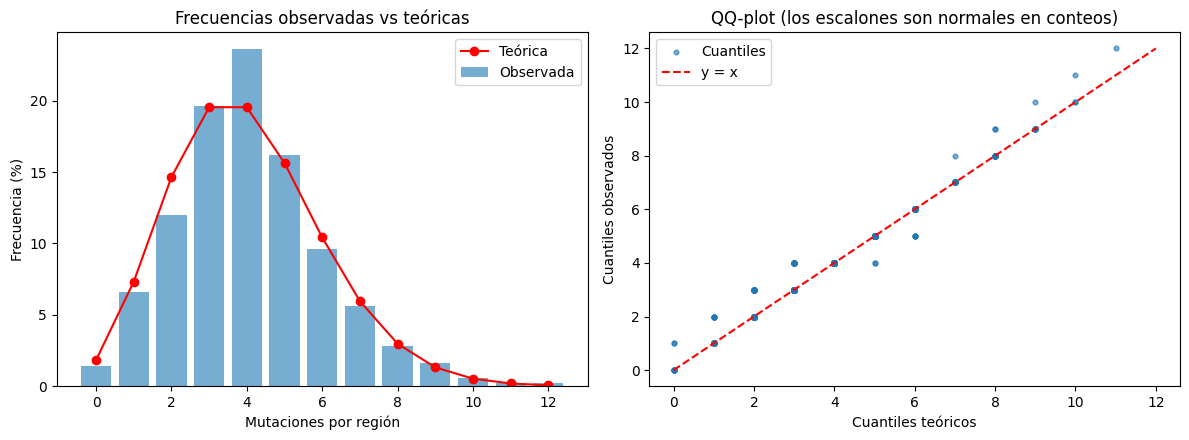


CASO 2: datos Gamma-Poisson (media 4, alfa 1)  ->  ajuste Poisson (FALLA)
Distribución teórica: poisson  {'mu': np.float64(4.124)}
  Media    -> empírica 4.124 | teórica 4.124
  Varianza -> empírica 21.283 | teórica 4.124
  Índice de dispersión (s²/media): 5.161   (≈1 si es Poisson)
  Chi-cuadrado: estadístico=1479.42, gl=8, p-valor=0.0000
  -> Se RECHAZA H0: la distribución no ajusta a los datos.


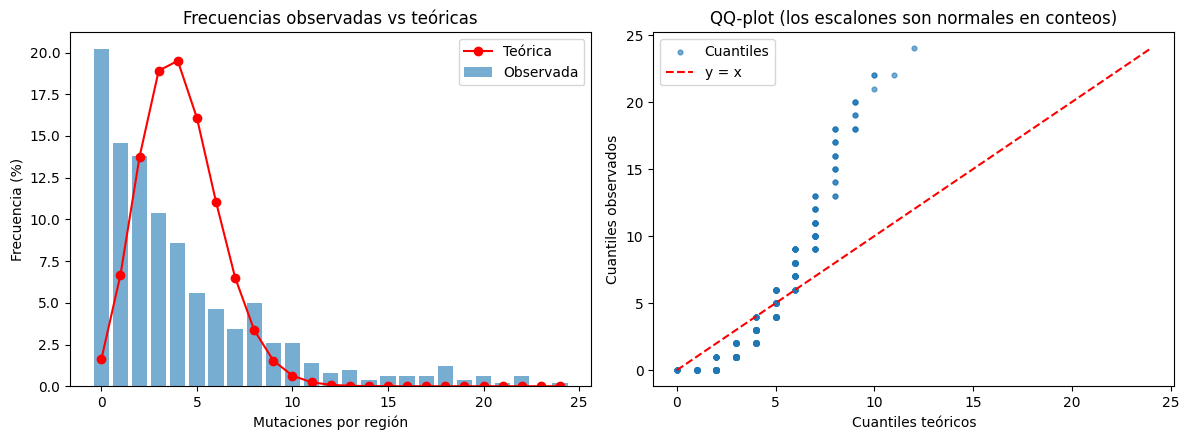


CASO 3: los mismos datos  ->  ajuste binomial negativa (AJUSTA)
Distribución teórica: nbinom  {'n': 1.0, 'p': np.float64(0.19516003122560502)}
  Media    -> empírica 4.124 | teórica 4.124
  Varianza -> empírica 21.283 | teórica 21.131
  Índice de dispersión (s²/media): 5.161   (≈1 si es Poisson)
  Chi-cuadrado: estadístico=14.14, gl=15, p-valor=0.5148
  -> NO se rechaza H0: el ajuste es razonable.


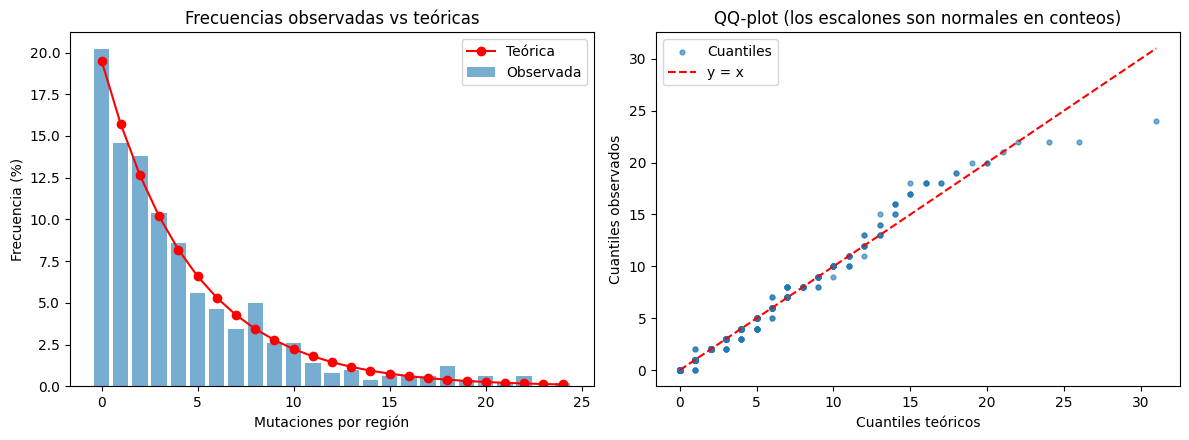

{'media_emp': np.float64(4.124),
 'var_emp': np.float64(21.28319038076152),
 'chi2': np.float64(14.142005789809282),
 'gl': 15,
 'p': np.float64(0.5147874993712669)}

In [ ]:
# 5a. DEMOSTRACIÓN: validación de la simulación (semilla fija -> resultados reproducibles)
rng_demo = np.random.default_rng(seed=2024)
MEDIA, ALFA = 4.0, 1.0

print("=" * 60)
print("CASO 1: datos Poisson(4)  ->  ajuste Poisson")
print("=" * 60)
datos_p = generar_datos(rng_demo, N, MEDIA)
validar(datos_p, stats.poisson, mu=MEDIA, parametros_estimados=0)

print("\n" + "=" * 60)
print("CASO 2: datos Gamma-Poisson (media 4, alfa 1)  ->  ajuste Poisson (FALLA)")
print("=" * 60)
datos_nb = generar_datos(rng_demo, N, MEDIA, ALFA)
validar(datos_nb, stats.poisson, mu=datos_nb.mean())

print("\n" + "=" * 60)
print("CASO 3: los mismos datos  ->  ajuste binomial negativa (AJUSTA)")
print("=" * 60)
validar(datos_nb, stats.nbinom, n=ALFA, p=ALFA / (ALFA + datos_nb.mean()))

### Cómo leer la salida de 5a
Con la semilla 2024 se obtuvo, aproximadamente:

| Caso | Índice de dispersión | p-valor del χ² | Conclusión |
|---|---|---|---|
| 1. Datos Poisson, ajuste Poisson | 0.94 | 0.48 | Ajusta |
| 2. Datos Gamma-Poisson, ajuste Poisson | 5.16 | 0.0000 | Poisson falla |
| 3. Mismos datos, ajuste NB | 5.16 | 0.51 | NB ajusta |

- En el caso 1 se usa el parámetro verdadero (`mu=4.0`) y `parametros_estimados=0`.
- En el caso 2 la media empírica coincide por construcción, pero la varianza es 21.3 y Poisson predice 4.1. Esa diferencia
  es la sobredispersión.
- En el caso 3 la varianza teórica de la NB (21.1) es casi igual a la empírica (21.3).

### 5b. Jugar
Ejecuta las 3 rondas interactivas. En Colab aparece un cuadro de texto debajo de la celda para escribir las respuestas.
Podés fijar una semilla en `default_rng(...)` si querés repetir las mismas rondas.

In [ ]:
# 5b. JUGAR (interactivo). Cambiá la semilla para obtener otras rondas.
rng_juego = np.random.default_rng()   # sin semilla: rondas distintas cada vez
jugar(rng_juego)

## Notas para el informe de validación
- **Por qué Poisson cuando no hay heterogeneidad:** eventos raros, independientes, tasa constante e igual exposición.
- **Por qué Gamma-Poisson / NB cuando hay heterogeneidad:** la tasa varía entre regiones (heterogeneidad), lo que
  aumenta la varianza: `Var = μ + μ²/α > μ`.
- **Evidencia de validación:** índice de dispersión ≈ 1 (Poisson) vs > 1 (NB), QQ-plot sobre la recta cuando el
  modelo es el correcto, y p-valor del χ² alto con el modelo correcto y ≈ 0 con Poisson sobre datos sobredispersos.
- **Limitación a mencionar:** el estimador usado es la media muestral; con tasas bajas y pocas regiones la
  estimación es más ruidosa (por eso se da una tolerancia del 30 % en el puntaje).